# Partie 3 — Espaces des degrés d'acceptabilité du weighted h-categorizer


In [1]:
# Paramètres (équivalents des options de la ligne de commande)
CUSTOM_AF = None      # --af, ex. "a,b,c : a>b, b>c, c>a"
N_SAMPLES = 100_000   # --n-samples
REPEATS = 10          # --repeats
EPSILON = 1e-10       # --epsilon
QUICK = False         # --quick
if QUICK:
    N_SAMPLES, REPEATS = 5_000, 3

In [2]:
import itertools
import json
import os
import string
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from scipy.spatial import ConvexHull, QhullError

%matplotlib inline

# racine du dépôt, que le notebook soit lancé depuis notebooks/ ou depuis la racine
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = Path(os.environ.get("PART3_OUT", ROOT / "results" / "part3"))
OUT.mkdir(parents=True, exist_ok=True)
CMAP = "magma"
BINS = 40

## 1. La sémantique weighted h-categorizer 


In [3]:
class ArgumentationFramework:
    """An abstract argumentation framework (A, R).

    `arguments` is a list of names, `attacks` a list of pairs (b, a) meaning
    "b attacks a". The attack matrix M has M[i, j] = 1 iff arguments[i]
    attacks arguments[j], so the sum of attacker degrees is x @ M.
    """

    def __init__(self, arguments, attacks, name=None):
        self.arguments = list(arguments)
        if len(set(self.arguments)) != len(self.arguments):
            raise ValueError("argument names must be unique")
        self.index = {a: i for i, a in enumerate(self.arguments)}
        self.attacks = []
        for b, a in attacks:
            if b not in self.index or a not in self.index:
                raise ValueError(f"attack ({b}, {a}) uses an unknown argument")
            if (b, a) not in self.attacks:
                self.attacks.append((b, a))
        self.name = name or "AF"
        n = len(self.arguments)
        self.matrix = np.zeros((n, n))
        for b, a in self.attacks:
            self.matrix[self.index[b], self.index[a]] = 1.0

    def __len__(self):
        return len(self.arguments)

    def attackers(self, a):
        return [b for b, target in self.attacks if target == a]

    def __repr__(self):
        rel = ", ".join(f"{b}->{a}" for b, a in self.attacks) or "no attack"
        return f"{self.name}(A={{{', '.join(self.arguments)}}}, R={{{rel}}})"

In [4]:
def h_categorizer(af, weights, epsilon=1e-8, max_iter=100_000, return_iterations=False):
    """Acceptability degrees of a single weight vector.

    `weights` is a dict {argument: weight} or a sequence ordered like
    `af.arguments`. Returns a dict {argument: degree}.
    """
    if epsilon <= 0:
        raise ValueError("epsilon must be > 0")
    if isinstance(weights, dict):
        w = np.array([weights[a] for a in af.arguments], dtype=float)
    else:
        w = np.asarray(weights, dtype=float)
    if w.shape != (len(af),):
        raise ValueError(f"expected {len(af)} weights, got shape {w.shape}")
    if np.any(w < 0) or np.any(w > 1):
        raise ValueError("weights must lie in [0, 1]")

    x, iterations = h_categorizer_batch(af, w[None, :], epsilon, max_iter, return_iterations=True)
    degrees = dict(zip(af.arguments, x[0]))
    return (degrees, iterations) if return_iterations else degrees

In [5]:
def h_categorizer_batch(af, W, epsilon=1e-8, max_iter=100_000, return_iterations=False):
    """Vectorised h-categorizer for many weight vectors at once.

    `W` has shape (N, |A|), one weight vector per row. All rows are iterated
    together; the loop stops when every row has moved by less than epsilon
    on every argument. Returns X of shape (N, |A|).
    """
    if epsilon <= 0:
        raise ValueError("epsilon must be > 0")
    W = np.asarray(W, dtype=float)
    M = af.matrix
    x = W.copy()
    for k in range(1, max_iter + 1):
        x_new = W / (1.0 + x @ M)
        delta = np.max(np.abs(x_new - x)) if x.size else 0.0
        x = x_new
        if delta < epsilon:
            return (x, k) if return_iterations else x
    raise RuntimeError(f"no convergence after {max_iter} iterations (last delta={delta:.3g})")

## 2. Catalogue de frameworks


In [6]:
def _names(n):
    return list(string.ascii_lowercase[:n])

In [7]:
def isolated(n):
    return ArgumentationFramework(_names(n), [], name=f"isolated{n}")

In [8]:
def chain(n):
    a = _names(n)
    return ArgumentationFramework(a, [(a[i], a[i + 1]) for i in range(n - 1)], name=f"chain{n}")

In [9]:
def cycle(n):
    a = _names(n)
    return ArgumentationFramework(a, [(a[i], a[(i + 1) % n]) for i in range(n)], name=f"cycle{n}")

In [10]:
def complete(n):
    a = _names(n)
    return ArgumentationFramework(a, [(x, y) for x, y in itertools.permutations(a, 2)], name=f"complete{n}")

In [11]:
def star(n):
    """n-1 unattacked arguments all attacking the last one."""
    a = _names(n)
    return ArgumentationFramework(a, [(x, a[-1]) for x in a[:-1]], name=f"star{n}")

In [12]:
def random_af(n, p, seed):
    """Erdős–Rényi digraph without self-attacks."""
    rng = np.random.default_rng(seed)
    a = _names(n)
    att = [(x, y) for x, y in itertools.permutations(a, 2) if rng.random() < p]
    return ArgumentationFramework(a, att, name=f"random{n}_p{p}_s{seed}")

In [13]:
def parse(spec, name=None):
    """Parse 'a,b,c : a>b, b>c, c>a' into an ArgumentationFramework."""
    if ":" in spec:
        args_part, att_part = spec.split(":", 1)
    else:
        args_part, att_part = spec, ""
    arguments = [s.strip() for s in args_part.split(",") if s.strip()]
    attacks = []
    for item in att_part.split(","):
        item = item.strip()
        if not item:
            continue
        b, a = (s.strip() for s in item.split(">"))
        attacks.append((b, a))
    return ArgumentationFramework(arguments, attacks, name=name or "custom")

In [14]:
def small_frameworks():
    """Hand-made frameworks whose degrees have closed forms (used in tests)."""
    return {
        "isolated2": isolated(2),
        "attack2": ArgumentationFramework(["a", "b"], [("a", "b")], name="attack2"),
        "mutual2": ArgumentationFramework(["a", "b"], [("a", "b"), ("b", "a")], name="mutual2"),
        "self1": ArgumentationFramework(["a"], [("a", "a")], name="self1"),
        "chain3": chain(3),
        "cycle3": cycle(3),
        "star3": star(3),
    }

In [15]:
def experiment_frameworks():
    """Frameworks studied in Part B, grouped by number of arguments."""
    afs = [
        isolated(2),
        ArgumentationFramework(["a", "b"], [("a", "b")], name="attack2"),
        ArgumentationFramework(["a", "b"], [("a", "b"), ("b", "a")], name="mutual2"),
        ArgumentationFramework(["a", "b"], [("a", "b"), ("b", "b")], name="attack2_self"),
        chain(3),
        cycle(3),
        star(3),
        complete(3),
        chain(4),
        cycle(4),
        complete(4),
        random_af(4, 0.4, seed=1),
        chain(5),
        cycle(5),
        random_af(5, 0.3, seed=2),
        cycle(6),
        random_af(6, 0.3, seed=3),
    ]
    return afs

## 3. Espace des degrés 

In [16]:
def sample_space(af, n_samples=100_000, seed=0, epsilon=1e-10):
    """Draw n_samples weight vectors in [0,1]^|A| and map them to degrees."""
    rng = np.random.default_rng(seed)
    W = rng.random((n_samples, len(af)))
    X, iterations = h_categorizer_batch(af, W, epsilon, return_iterations=True)
    return W, X, iterations

In [17]:
def inverse_weights(af, X):
    """g(x) = x * (1 + x @ M): the weights that produce the degrees x."""
    return X * (1.0 + X @ af.matrix)

In [18]:
def in_space(af, X, tol=1e-12):
    """Membership test for S (exact characterisation, see module docstring)."""
    return np.all(X >= -tol, axis=-1) & np.all(inverse_weights(af, X) <= 1 + tol, axis=-1)

In [19]:
def jacobian_det(af, X):
    """det of the Jacobian of g at each row of X.

    dg_a/dx_c = delta_ac (1 + s_a) + x_a M[c, a], with s = x @ M.
    """
    X = np.atleast_2d(X)
    M = af.matrix
    S = X @ M
    J = np.einsum("ka,ca->kac", X, M)
    idx = np.arange(len(af))
    J[:, idx, idx] += 1.0 + S
    return np.linalg.det(J)

In [20]:
def exact_density(af, X):
    """Density of x = HCat(w), w ~ U[0,1]^n, evaluated at X (0 outside S)."""
    return np.where(in_space(af, X), np.abs(jacobian_det(af, X)), 0.0)

In [21]:
def true_volume(af, X_samples):
    """Volume of S estimated without bias as E_w[1 / |det Jg(HCat(w))|]."""
    inv = 1.0 / np.abs(jacobian_det(af, X_samples))
    return inv.mean(), inv.std(ddof=1) / np.sqrt(len(inv))

In [22]:
def convex_hull(X, max_dim=6):
    """Convex hull of the points (None if too high-dimensional or degenerate)."""
    n = X.shape[1]
    if n == 1:
        return None
    if n > max_dim:
        return None
    try:
        return ConvexHull(X, qhull_options="Qx" if n > 4 else "")
    except QhullError:
        return None

In [23]:
def hull_volume(X, hull=None):
    if X.shape[1] == 1:
        return float(X.max() - X.min())
    hull = hull if hull is not None else convex_hull(X)
    return float(hull.volume) if hull is not None else float("nan")

In [24]:
def hull_gap(af, hull, n_probe=200_000, seed=123):
    """Fraction of the hull volume that lies outside S (empty space of the hull).

    Points are drawn uniformly in the hull's bounding box, kept if inside the
    hull, then tested for membership in S.
    """
    rng = np.random.default_rng(seed)
    lo, hi = hull.points[hull.vertices].min(0), hull.points[hull.vertices].max(0)
    P = lo + (hi - lo) * rng.random((n_probe, hull.points.shape[1]))
    A, b = hull.equations[:, :-1].T, hull.equations[:, -1]
    inside_hull = np.concatenate([np.all(C @ A + b <= 1e-12, axis=1)
                                  for C in np.array_split(P, max(1, len(P) // 2000))])
    P = P[inside_hull]
    return float(1.0 - in_space(af, P).mean()), len(P)

In [25]:
def density_2d(X, i, j, bins=40, rng_box=((0, 1), (0, 1))):
    """Normalised 2-D histogram (probability mass per cell) of columns i, j."""
    H, xe, ye = np.histogram2d(X[:, i], X[:, j], bins=bins, range=rng_box)
    return H / H.sum(), xe, ye

In [26]:
def exact_cell_mass_2d(af, bins=40, sub=16):
    """Exact probability mass per cell for a 2-argument framework (midpoint rule)."""
    assert len(af) == 2
    m = bins * sub
    c = (np.arange(m) + 0.5) / m
    gx, gy = np.meshgrid(c, c, indexing="ij")
    P = np.stack([gx.ravel(), gy.ravel()], axis=1)
    dens = exact_density(af, P).reshape(m, m) / m**2
    return dens.reshape(bins, sub, bins, sub).sum(axis=(1, 3))

In [27]:
def total_variation(P, Q):
    return 0.5 * np.abs(P - Q).sum()

In [28]:
def jensen_shannon(P, Q):
    P, Q = P.ravel(), Q.ravel()
    Mx = 0.5 * (P + Q)

    def kl(A, B):
        mask = A > 0
        return np.sum(A[mask] * np.log2(A[mask] / B[mask]))

    return np.sqrt(0.5 * kl(P, Mx) + 0.5 * kl(Q, Mx))

In [29]:
def high_density_region(H, quantile_mass=0.5):
    """Smallest set of cells holding `quantile_mass` of the probability."""
    flat = H.ravel()
    order = np.argsort(flat)[::-1]
    k = np.searchsorted(np.cumsum(flat[order]), quantile_mass) + 1
    mask = np.zeros(flat.shape, bool)
    mask[order[:k]] = True
    return mask.reshape(H.shape)

In [30]:
def jaccard(A, B):
    return (A & B).sum() / max((A | B).sum(), 1)

In [31]:
def pairs(n):
    return list(itertools.combinations(range(n), 2))

In [32]:
def resampling_study(af, n_samples=100_000, n_repeats=10, bins=40, epsilon=1e-10, base_seed=1000):
    """Stability of hull and heat-maps across independent re-samplings."""
    hists, volumes, hdr = [], [], []
    for r in range(n_repeats):
        _, X, _ = sample_space(af, n_samples, seed=base_seed + r, epsilon=epsilon)
        hs = [density_2d(X, i, j, bins)[0] for i, j in pairs(len(af))]
        hists.append(hs)
        hdr.append([high_density_region(h) for h in hs])
        volumes.append(hull_volume(X))
    tv, js, jac, maxrel = [], [], [], []
    for r, s in itertools.combinations(range(n_repeats), 2):
        for p in range(len(pairs(len(af)))):
            P, Q = hists[r][p], hists[s][p]
            tv.append(total_variation(P, Q))
            js.append(jensen_shannon(P, Q))
            jac.append(jaccard(hdr[r][p], hdr[s][p]))
            dense = (P + Q) / 2 > 1.0 / bins**2  # cells above the uniform level
            if dense.any():
                maxrel.append(np.max(np.abs(P - Q)[dense] / ((P + Q)[dense] / 2)))
    volumes = np.array(volumes)
    return {
        "tv_mean": float(np.mean(tv)), "tv_max": float(np.max(tv)),
        "js_mean": float(np.mean(js)),
        "hdr50_jaccard_mean": float(np.mean(jac)), "hdr50_jaccard_min": float(np.min(jac)),
        "dense_cell_max_rel_diff": float(np.max(maxrel)) if maxrel else float("nan"),
        "hull_volume_mean": float(volumes.mean()),
        "hull_volume_rel_std": float(volumes.std(ddof=1) / volumes.mean()),
        "hists_first_two": (hists[0], hists[1]),
    }

In [33]:
def tv_vs_sample_size(af, sizes, n_repeats=5, bins=40, reference_size=2_000_000, seed=7):
    """TV distance between a sample's heat-map and a reference heat-map, vs N.

    For |A| = 2 the reference is exact (integrated density); otherwise it is
    a very large independent sample. Only the (0, 1) projection is used.
    """
    if len(af) == 2:
        ref = exact_cell_mass_2d(af, bins)
    else:
        _, Xr, _ = sample_space(af, reference_size, seed=seed)
        ref = density_2d(Xr, 0, 1, bins)[0]
    out = {}
    for N in sizes:
        vals = []
        for r in range(n_repeats):
            _, X, _ = sample_space(af, N, seed=seed + 100 + r)
            vals.append(total_variation(density_2d(X, 0, 1, bins)[0], ref))
        out[N] = (float(np.mean(vals)), float(np.std(vals)))
    return out

## 4. Fonctions de tracé et d'analyse

In [34]:
def _hull_outline(ax, P, **kw):
    """Draw the 2-D convex hull of points P (projection of the n-D hull)."""
    h = ConvexHull(P)
    v = np.append(h.vertices, h.vertices[0])
    ax.plot(P[v, 0], P[v, 1], **kw)

In [35]:
def _boundary_2d(ax, af, i=0, j=1):
    """True boundary of S for a 2-argument framework (level set of g)."""
    m = 400
    c = np.linspace(0, 1, m)
    gx, gy = np.meshgrid(c, c, indexing="ij")
    P = np.stack([gx.ravel(), gy.ravel()], 1)
    F = (inverse_weights(af, P).max(1) - 1).reshape(m, m)
    ax.contour(gx, gy, F, levels=[0], colors="deepskyblue", linewidths=1.5, linestyles="--")

In [36]:
def _heatmap(ax, X, i, j, af, vmax=None):
    H, xe, ye = density_2d(X, i, j, BINS)
    dens = H * BINS**2  # probability per unit area
    im = ax.imshow(dens.T, origin="lower", extent=(0, 1, 0, 1), cmap=CMAP, vmax=vmax,
                   aspect="equal", interpolation="nearest")
    _hull_outline(ax, X[:, [i, j]], color="cyan", lw=1)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    return im

In [37]:
def plot_2d(af, X, path):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
    a, b = af.arguments
    sub = X[np.random.default_rng(0).choice(len(X), min(8000, len(X)), replace=False)]
    ax = axes[0]
    ax.scatter(sub[:, 0], sub[:, 1], s=1, alpha=0.4, color="tab:gray")
    _hull_outline(ax, X, color="crimson", lw=2, label="convex hull")
    _boundary_2d(ax, af)
    ax.plot([], [], "--", color="deepskyblue", label="true boundary of S")
    ax.legend(loc="upper right", fontsize=8)
    ax.set_title("points $x_i$ (8k shown) and convex hull")

    vmax = np.percentile(density_2d(X, 0, 1, BINS)[0] * BINS**2, 99.5)
    im = _heatmap(axes[1], X, 0, 1, af, vmax=vmax)
    axes[1].set_title(f"empirical density, N={len(X):,}")
    fig.colorbar(im, ax=axes[1], fraction=0.046)

    m = 300
    c = (np.arange(m) + 0.5) / m
    gx, gy = np.meshgrid(c, c, indexing="ij")
    D = exact_density(af, np.stack([gx.ravel(), gy.ravel()], 1)).reshape(m, m)
    D = np.ma.masked_equal(D, 0)
    im = axes[2].imshow(D.T, origin="lower", extent=(0, 1, 0, 1), cmap=CMAP, vmax=vmax, aspect="equal")
    axes[2].set_title(r"exact density $|\det J_g(x)|$")
    fig.colorbar(im, ax=axes[2], fraction=0.046)
    for ax in axes:
        ax.set_xlabel(f"Deg({a})")
        ax.set_ylabel(f"Deg({b})")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
    fig.suptitle(repr(af))
    fig.tight_layout()
    fig.savefig(path, dpi=130)
    plt.show()

In [38]:
def plot_3d(af, X, hull, path):
    fig = plt.figure(figsize=(17, 5))
    ax = fig.add_subplot(1, 4, 1, projection="3d")
    tri = Poly3DCollection([X[s] for s in hull.simplices], alpha=0.12, facecolor="crimson",
                           edgecolor="crimson", linewidth=0.15)
    ax.add_collection3d(tri)
    sub = X[np.random.default_rng(0).choice(len(X), min(6000, len(X)), replace=False)]
    d = exact_density(af, sub)
    sc = ax.scatter(sub[:, 0], sub[:, 1], sub[:, 2], c=d, cmap=CMAP, s=2)
    fig.colorbar(sc, ax=ax, fraction=0.03, pad=0.1, label="density")
    ax.set_xlabel(af.arguments[0])
    ax.set_ylabel(af.arguments[1])
    ax.set_zlabel(af.arguments[2])
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_zlim(0, 1)
    ax.view_init(elev=22, azim=-60)
    ax.set_title("convex hull + points coloured by density", fontsize=9)
    for k, (i, j) in enumerate(pairs(3)):
        axk = fig.add_subplot(1, 4, k + 2)
        im = _heatmap(axk, X, i, j, af)
        axk.set_xlabel(f"Deg({af.arguments[i]})")
        axk.set_ylabel(f"Deg({af.arguments[j]})")
        fig.colorbar(im, ax=axk, fraction=0.046)
    fig.suptitle(repr(af))
    fig.tight_layout()
    fig.savefig(path, dpi=130)
    plt.show()

In [39]:
def plot_pairs(af, X, path):
    n = len(af)
    fig, axes = plt.subplots(n, n, figsize=(2.4 * n, 2.4 * n))
    for i in range(n):
        for j in range(n):
            ax = axes[i, j]
            if i == j:
                ax.hist(X[:, i], bins=60, range=(0, 1), color="tab:purple", density=True)
                ax.set_xlim(0, 1)
            elif i > j:
                _heatmap(ax, X, j, i, af)
            else:
                ax.axis("off")
                r = np.corrcoef(X[:, i], X[:, j])[0, 1]
                attack = ("→" if af.matrix[i, j] else "") + ("←" if af.matrix[j, i] else "")
                ax.text(0.5, 0.5, f"{af.arguments[i]} {attack or '·'} {af.arguments[j]}\nρ = {r:+.2f}",
                        ha="center", va="center", fontsize=10)
            ax.tick_params(labelsize=6)
            if j == 0:
                ax.set_ylabel(af.arguments[i])
            if i == n - 1:
                ax.set_xlabel(af.arguments[j])
    fig.suptitle(repr(af) + "\nlower: 2-D projected density + projected hull; diagonal: marginal", fontsize=10)
    fig.tight_layout()
    fig.savefig(path, dpi=110)
    plt.show()

In [40]:
def plot_resampling(af, res, path):
    P, Q = res["hists_first_two"][0][0], res["hists_first_two"][1][0]
    i, j = pairs(len(af))[0]
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    vmax = max(P.max(), Q.max()) * BINS**2
    for ax, H, t in ((axes[0], P, "sample 1"), (axes[1], Q, "sample 2")):
        im = ax.imshow(H.T * BINS**2, origin="lower", extent=(0, 1, 0, 1), cmap=CMAP, vmax=vmax)
        ax.set_title(t)
        fig.colorbar(im, ax=ax, fraction=0.046)
    D = (P - Q) * BINS**2
    lim = np.abs(D).max()
    im = axes[2].imshow(D.T, origin="lower", extent=(0, 1, 0, 1), cmap="RdBu_r", vmin=-lim, vmax=lim)
    axes[2].set_title(f"difference (TV = {total_variation(P, Q):.4f})")
    fig.colorbar(im, ax=axes[2], fraction=0.046)
    for ax in axes:
        ax.set_xlabel(f"Deg({af.arguments[i]})")
        ax.set_ylabel(f"Deg({af.arguments[j]})")
    fig.suptitle(f"{af.name}: two independent re-samplings of N = 100,000")
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.show()

In [41]:
def convergence_study(afs, path, n_samples=20_000):
    """Error to the fixed point vs iteration, and iterations vs epsilon."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    table = {}
    eps_list = [1e-2, 1e-4, 1e-6, 1e-8, 1e-10, 1e-12]
    W = np.random.default_rng(0).random((n_samples, 6))
    for af in afs:
        Wn = W[:, : len(af)]
        ref = h_categorizer_batch(af, Wn, 1e-15)
        x, errs = Wn.copy(), []
        for _ in range(60):
            x = Wn / (1 + x @ af.matrix)
            errs.append(np.abs(x - ref).max())
        axes[0].semilogy(range(1, 61), np.maximum(errs, 1e-17), label=af.name)
        iters = []
        for eps in eps_list:
            X, k = h_categorizer_batch(af, Wn, eps, return_iterations=True)
            iters.append(k)
        err_final = {eps: float(np.abs(h_categorizer_batch(af, Wn, eps) - ref).max()) for eps in eps_list}
        table[af.name] = {"iterations": dict(zip(map(str, eps_list), iters)),
                          "max_error": {str(k): v for k, v in err_final.items()}}
        axes[1].semilogx(eps_list, iters, "o-", label=af.name)
    axes[0].set_xlabel("iteration k")
    axes[0].set_ylabel(r"$\max_{i,a}|f^k_i(a) - Deg_i(a)|$")
    axes[0].set_title(f"distance to the fixed point ({n_samples:,} weight vectors)")
    axes[1].invert_xaxis()
    axes[1].set_xlabel("epsilon")
    axes[1].set_ylabel("iterations until max step < epsilon")
    axes[1].set_title("iterations needed vs epsilon")
    for ax in axes:
        ax.legend(fontsize=7)
        ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(path, dpi=130)
    plt.show()
    return table

In [42]:
def plot_tv_vs_n(curves, path):
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for name, c in curves.items():
        Ns = np.array(sorted(c))
        m = np.array([c[N][0] for N in Ns])
        s = np.array([c[N][1] for N in Ns])
        ax.errorbar(Ns, m, yerr=s, marker="o", capsize=3, label=name)
    Ns = np.array(sorted(next(iter(curves.values()))))
    ax.plot(Ns, 0.5 * np.sqrt(2 * BINS**2 / (np.pi * Ns)), "k:", label=r"$\propto 1/\sqrt{N}$ (theory)")
    ax.axvline(100_000, color="gray", lw=0.8, ls="--")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("number of samples N")
    ax.set_ylabel("TV distance to reference heat-map")
    ax.set_title(f"Heat-map error vs N ({BINS}x{BINS} cells)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3, which="both")
    fig.tight_layout()
    fig.savefig(path, dpi=130)
    plt.show()

In [43]:
def analyse(af, n_samples, n_repeats, epsilon):
    t0 = time.time()
    W, X, iters = sample_space(af, n_samples, seed=0, epsilon=epsilon)
    t_sample = time.time() - t0
    hull = convex_hull(X)
    hv = hull_volume(X, hull)
    tv, tv_se = true_volume(af, X)
    gap, _ = hull_gap(af, hull) if hull is not None else (float("nan"), 0)
    dens = np.abs(jacobian_det(af, X))
    n = len(af)
    if n == 2:
        plot_2d(af, X, OUT / f"space_{af.name}.png")
    elif n == 3:
        plot_3d(af, X, hull, OUT / f"space_{af.name}.png")
    else:
        plot_pairs(af, X, OUT / f"space_{af.name}.png")
    row = {
        "framework": af.name, "n_args": n, "n_attacks": len(af.attacks),
        "iterations": iters, "sampling_time_s": round(t_sample, 3),
        "hull_volume": hv, "hull_vertices": int(len(hull.vertices)) if hull is not None else 0,
        "true_volume": tv, "true_volume_se": tv_se,
        "hull_empty_fraction": gap,
        "density_min": float(dens.min()), "density_max": float(dens.max()),
        "mean_degree": X.mean(0).round(4).tolist(),
    }
    if n_repeats > 1:
        res = resampling_study(af, n_samples, n_repeats, BINS, epsilon)
        if af.name in ("attack2", "mutual2", "cycle3"):
            plot_resampling(af, res, OUT / f"resampling_{af.name}.png")
        res.pop("hists_first_two")
        row.update({f"resample_{k}": v for k, v in res.items()})
    return row

In [44]:
def write_markdown_table(rows, path):
    cols = [("framework", "AF"), ("n_args", "|A|"), ("n_attacks", "|R|"), ("iterations", "iter"),
            ("hull_volume", "vol(hull)"), ("true_volume", "vol(S)"), ("hull_empty_fraction", "empty in hull"),
            ("density_max", "max dens."), ("resample_tv_mean", "TV resample"),
            ("resample_hdr50_jaccard_mean", "Jaccard HDR50"), ("resample_hull_volume_rel_std", "CV vol(hull)")]
    lines = ["| " + " | ".join(c[1] for c in cols) + " |", "|" + "---|" * len(cols)]
    for r in rows:
        cells = []
        for k, _ in cols:
            v = r.get(k, "")
            if isinstance(v, float):
                v = f"{v:.2e}" if k == "resample_hull_volume_rel_std" else f"{v:.4f}"
            cells.append(str(v))
        lines.append("| " + " | ".join(cells) + " |")
    path.write_text("\n".join(lines) + "\n", encoding="utf-8")

## 5. Espaces des degrés de chaque framework

Pour chaque framework : échantillonnage de N vecteurs de poids, enveloppe convexe, volume exact, densité et ré-échantillonnage.

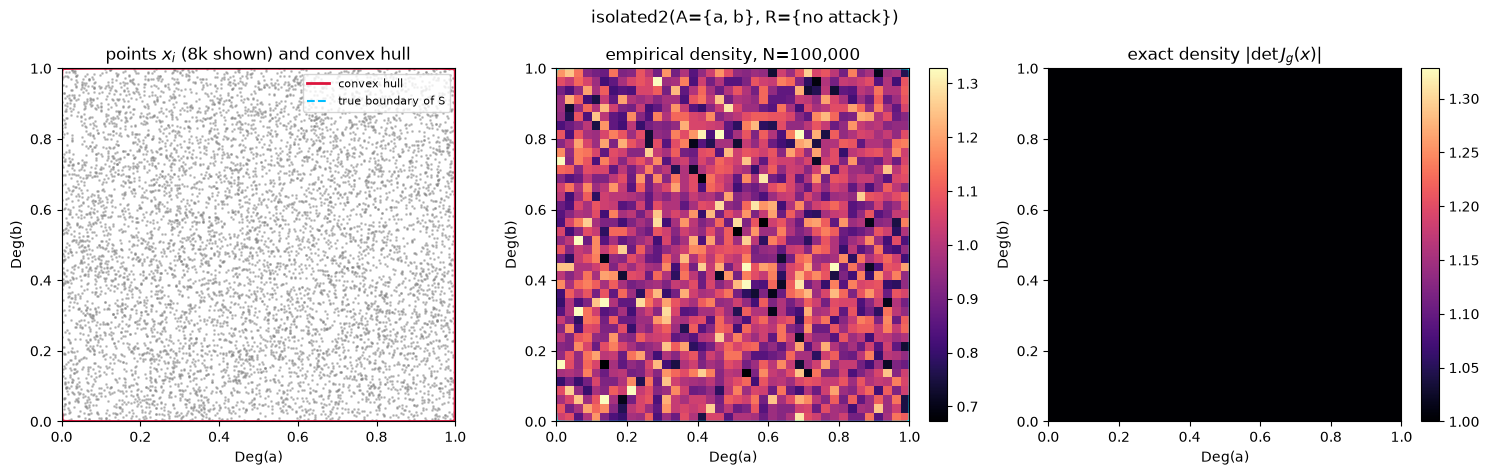

isolated2(A={a, b}, R={no attack}): done in 1.4s


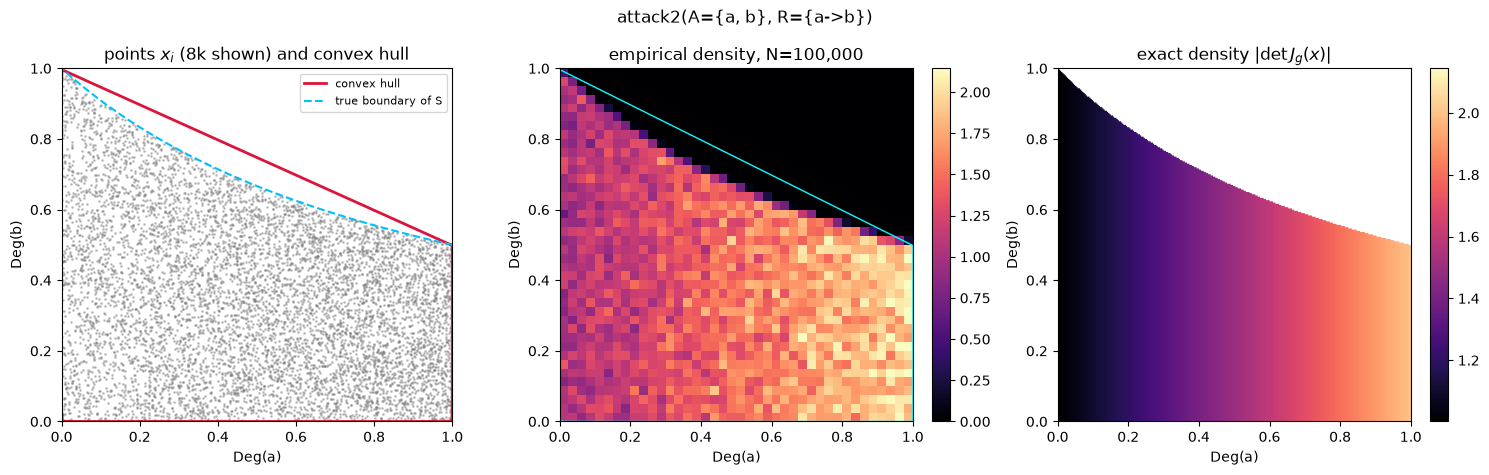

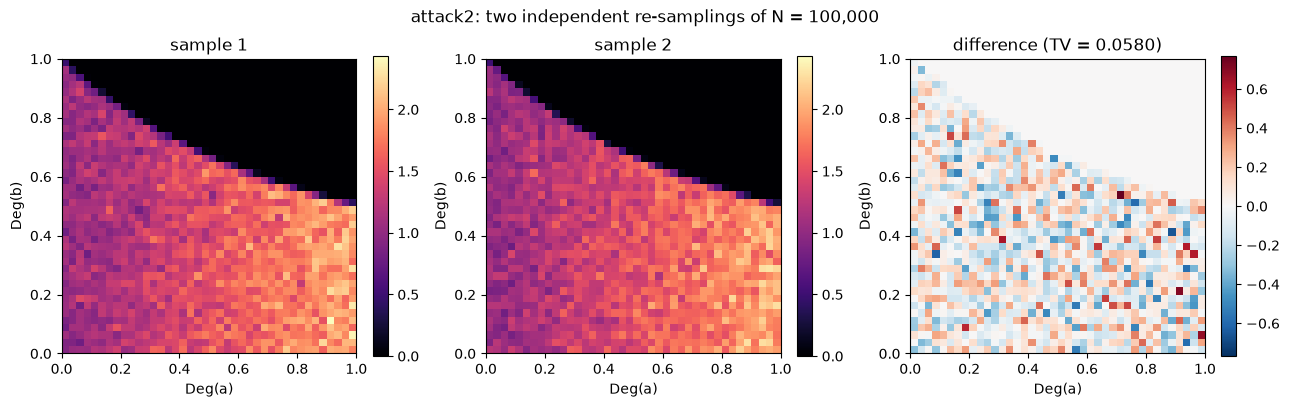

attack2(A={a, b}, R={a->b}): done in 2.9s


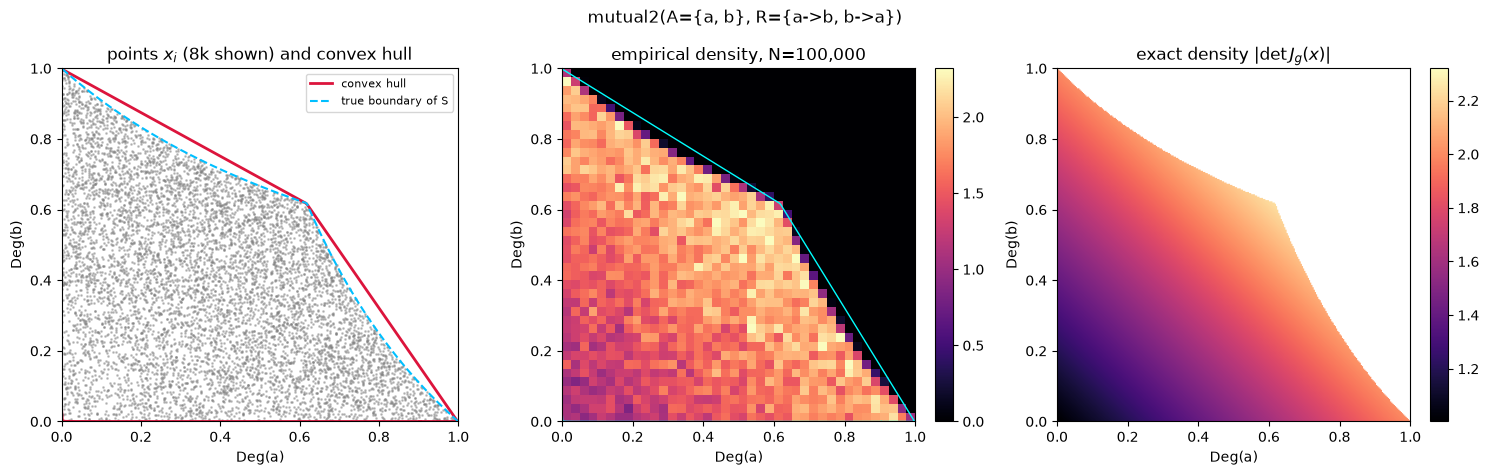

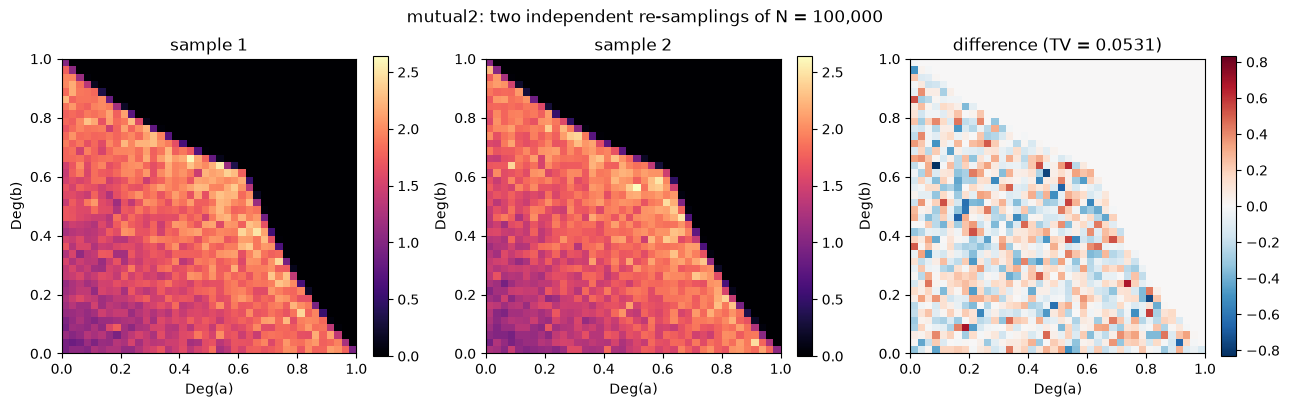

mutual2(A={a, b}, R={a->b, b->a}): done in 2.6s


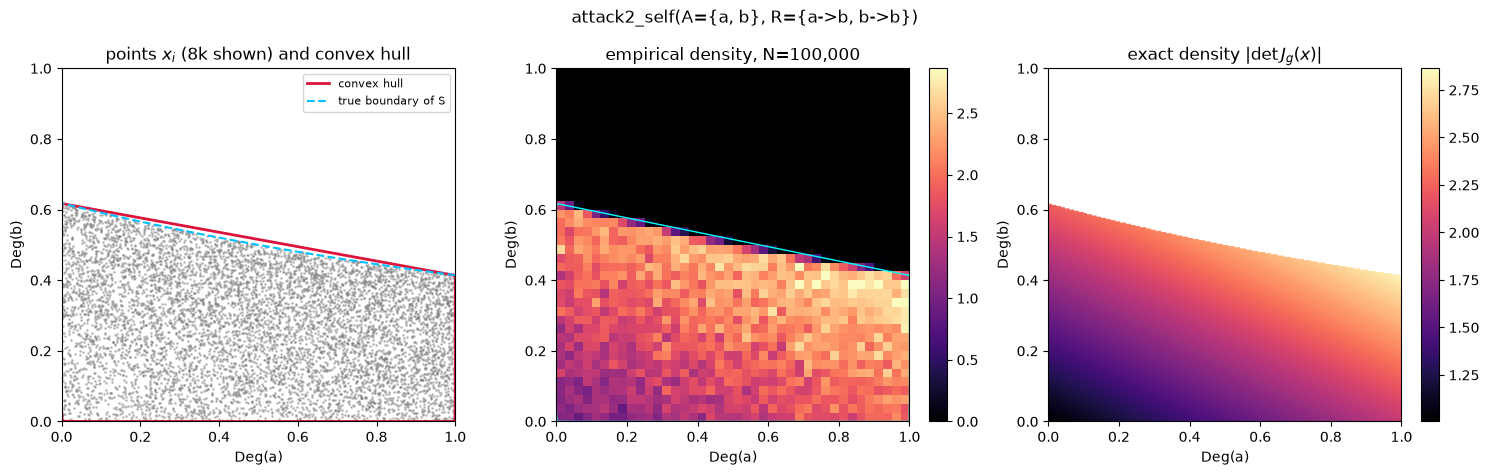

attack2_self(A={a, b}, R={a->b, b->b}): done in 1.9s


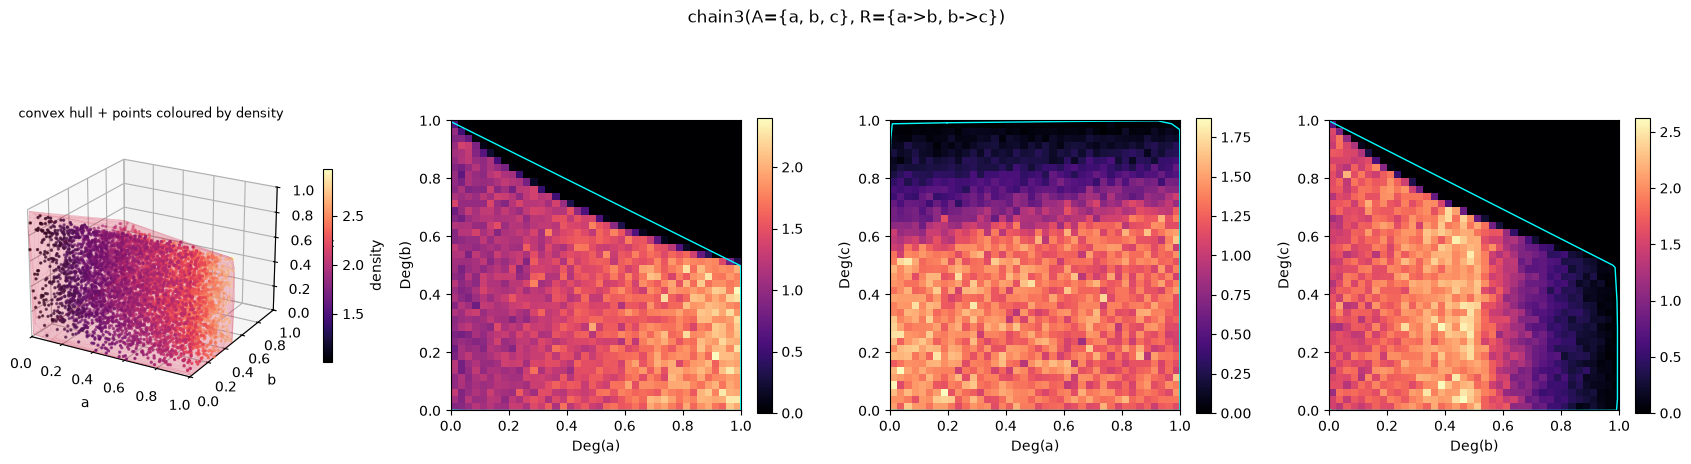

chain3(A={a, b, c}, R={a->b, b->c}): done in 2.0s


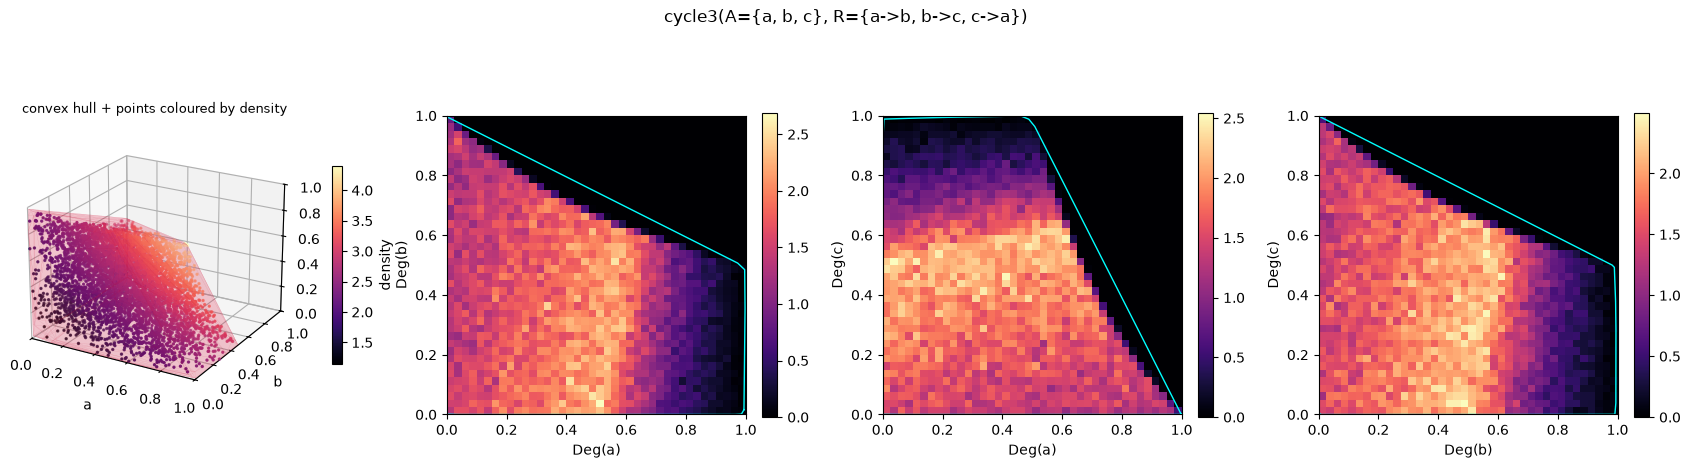

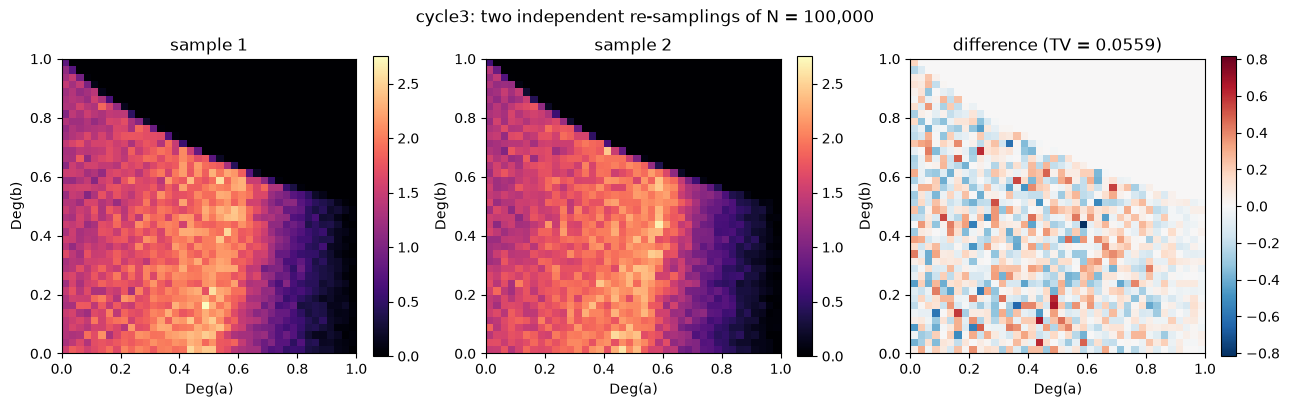

cycle3(A={a, b, c}, R={a->b, b->c, c->a}): done in 3.8s


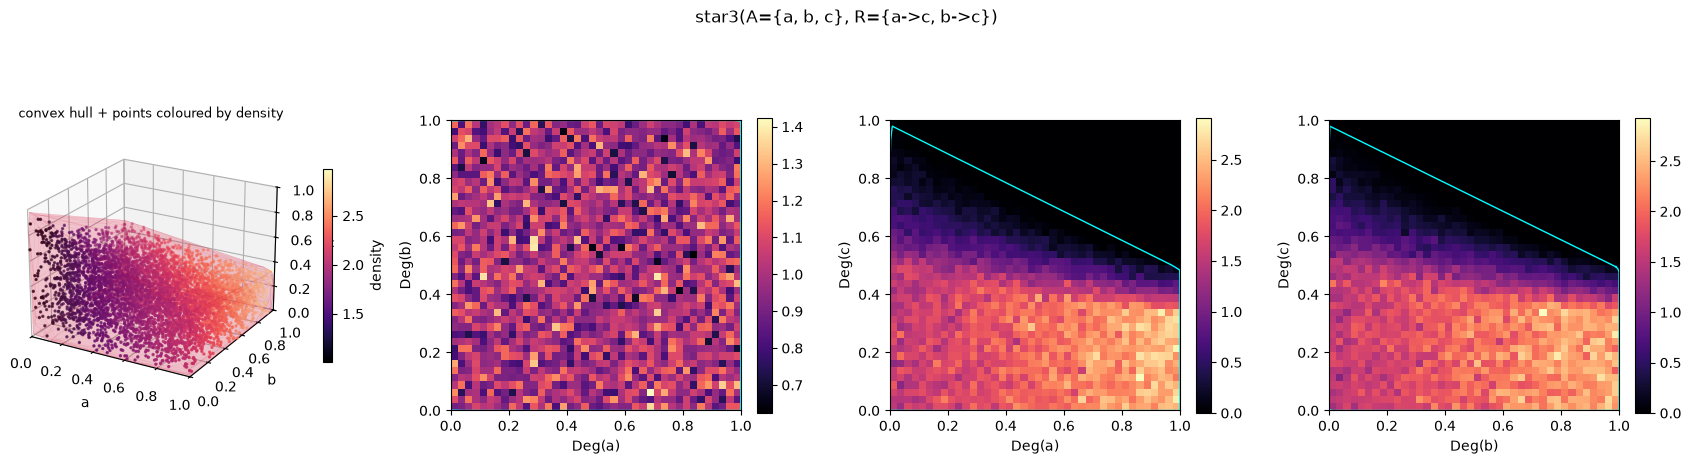

star3(A={a, b, c}, R={a->c, b->c}): done in 2.0s


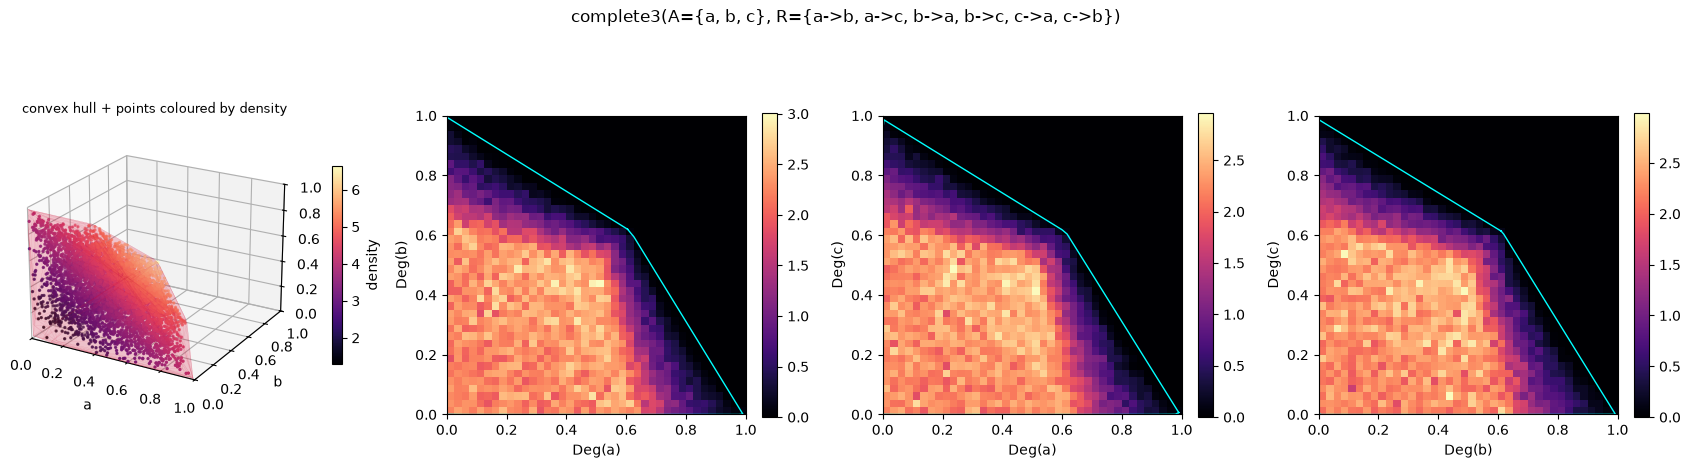

complete3(A={a, b, c}, R={a->b, a->c, b->a, b->c, c->a, c->b}): done in 4.1s


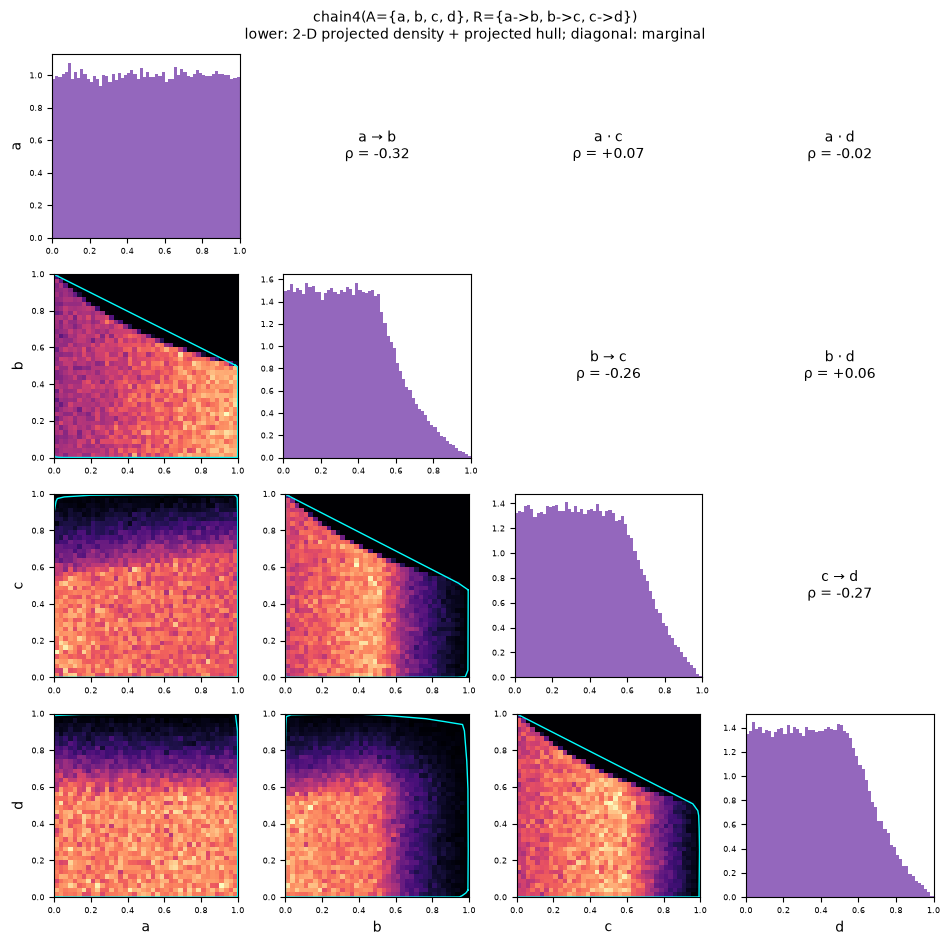

chain4(A={a, b, c, d}, R={a->b, b->c, c->d}): done in 11.3s


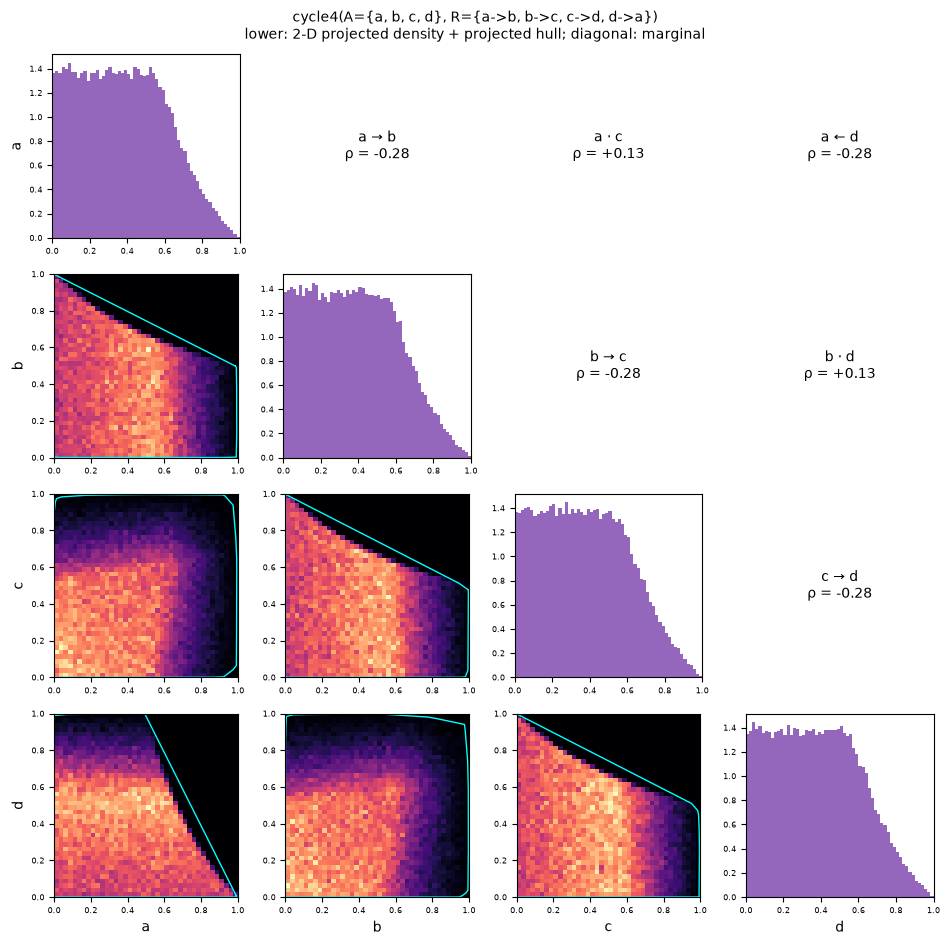

cycle4(A={a, b, c, d}, R={a->b, b->c, c->d, d->a}): done in 9.7s


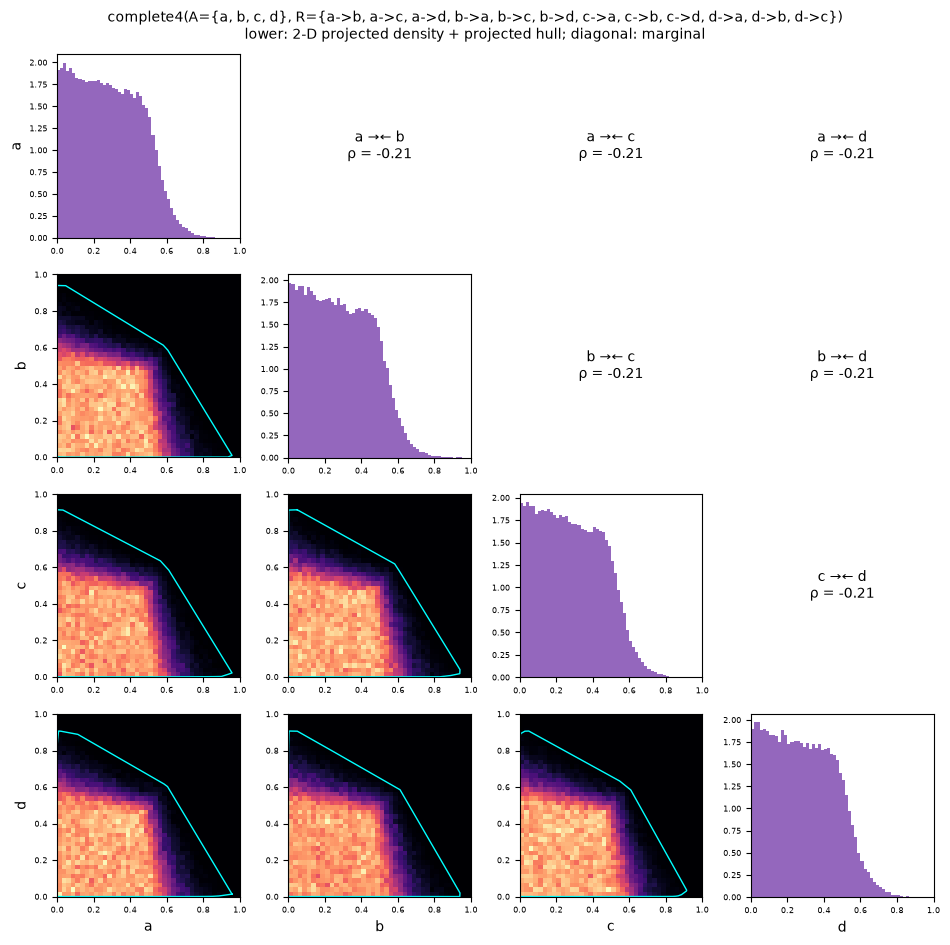

complete4(A={a, b, c, d}, R={a->b, a->c, a->d, b->a, b->c, b->d, c->a, c->b, c->d, d->a, d->b, d->c}): done in 9.9s


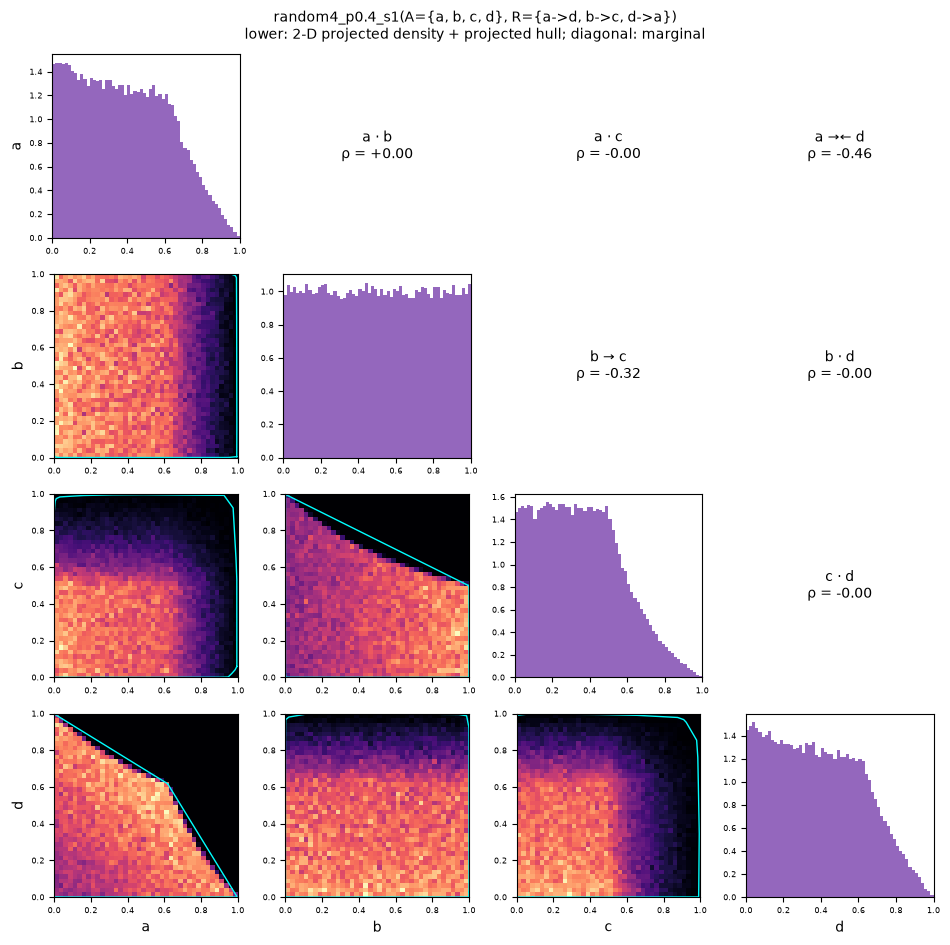

random4_p0.4_s1(A={a, b, c, d}, R={a->d, b->c, d->a}): done in 9.5s


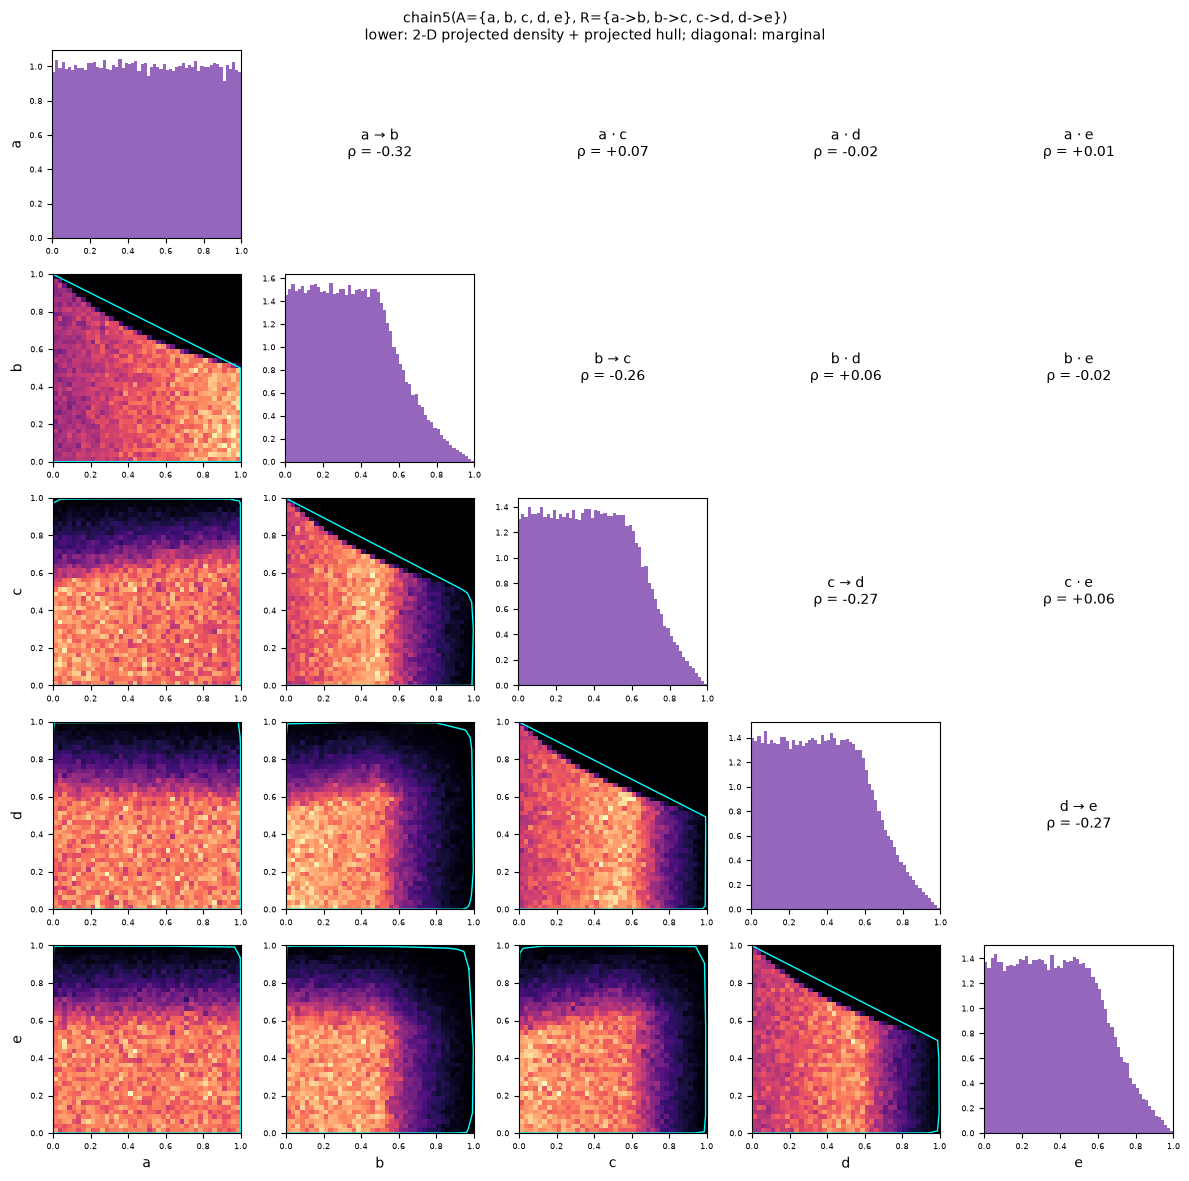

chain5(A={a, b, c, d, e}, R={a->b, b->c, c->d, d->e}): done in 71.6s


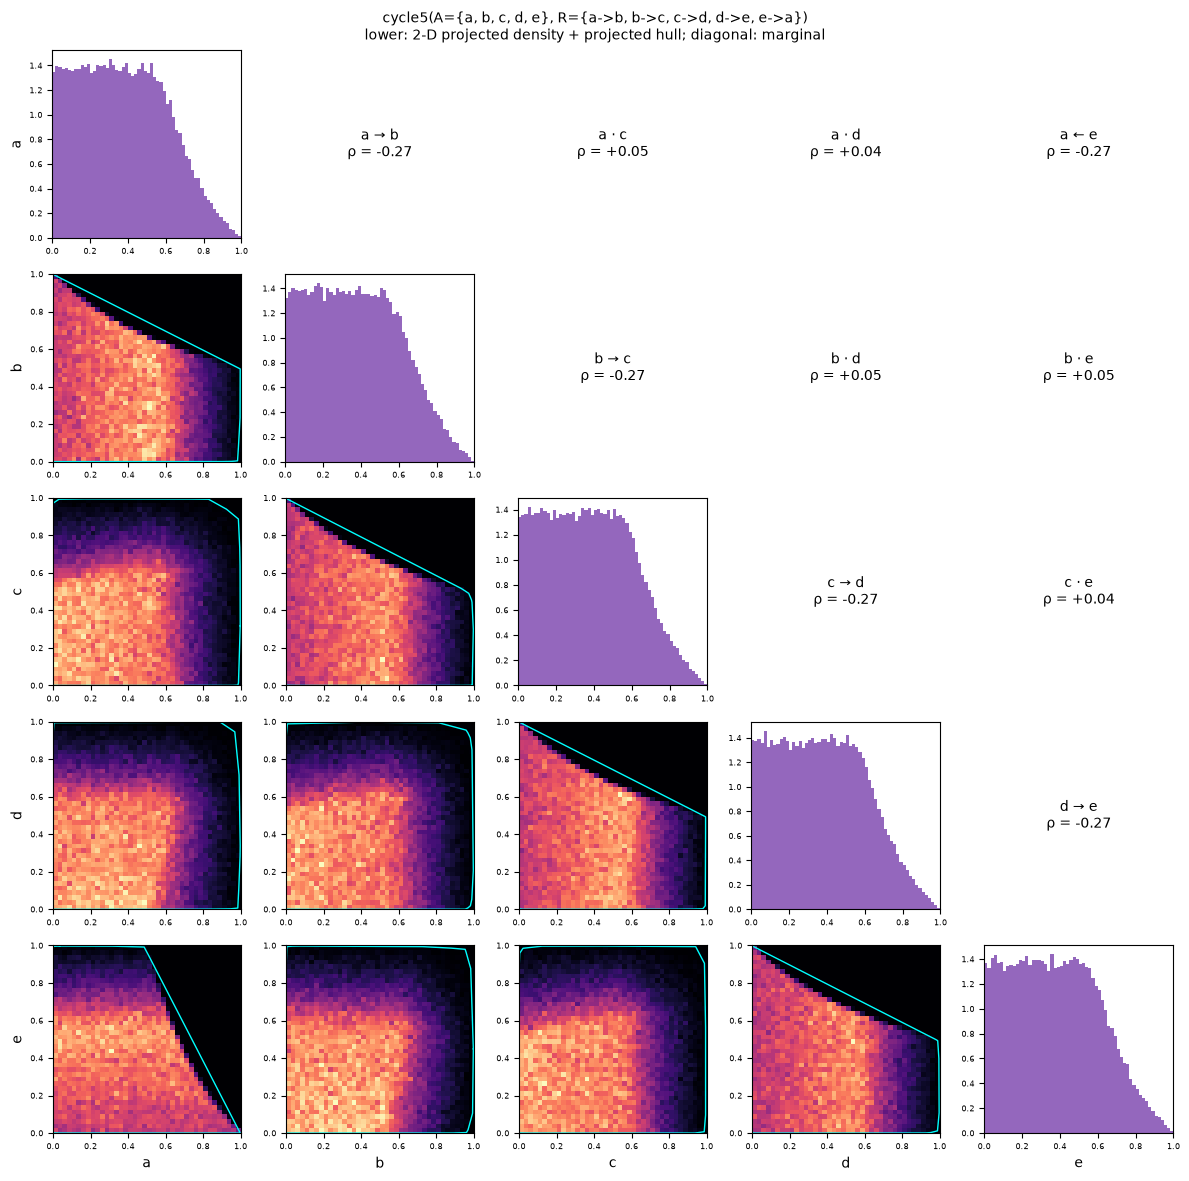

cycle5(A={a, b, c, d, e}, R={a->b, b->c, c->d, d->e, e->a}): done in 58.9s


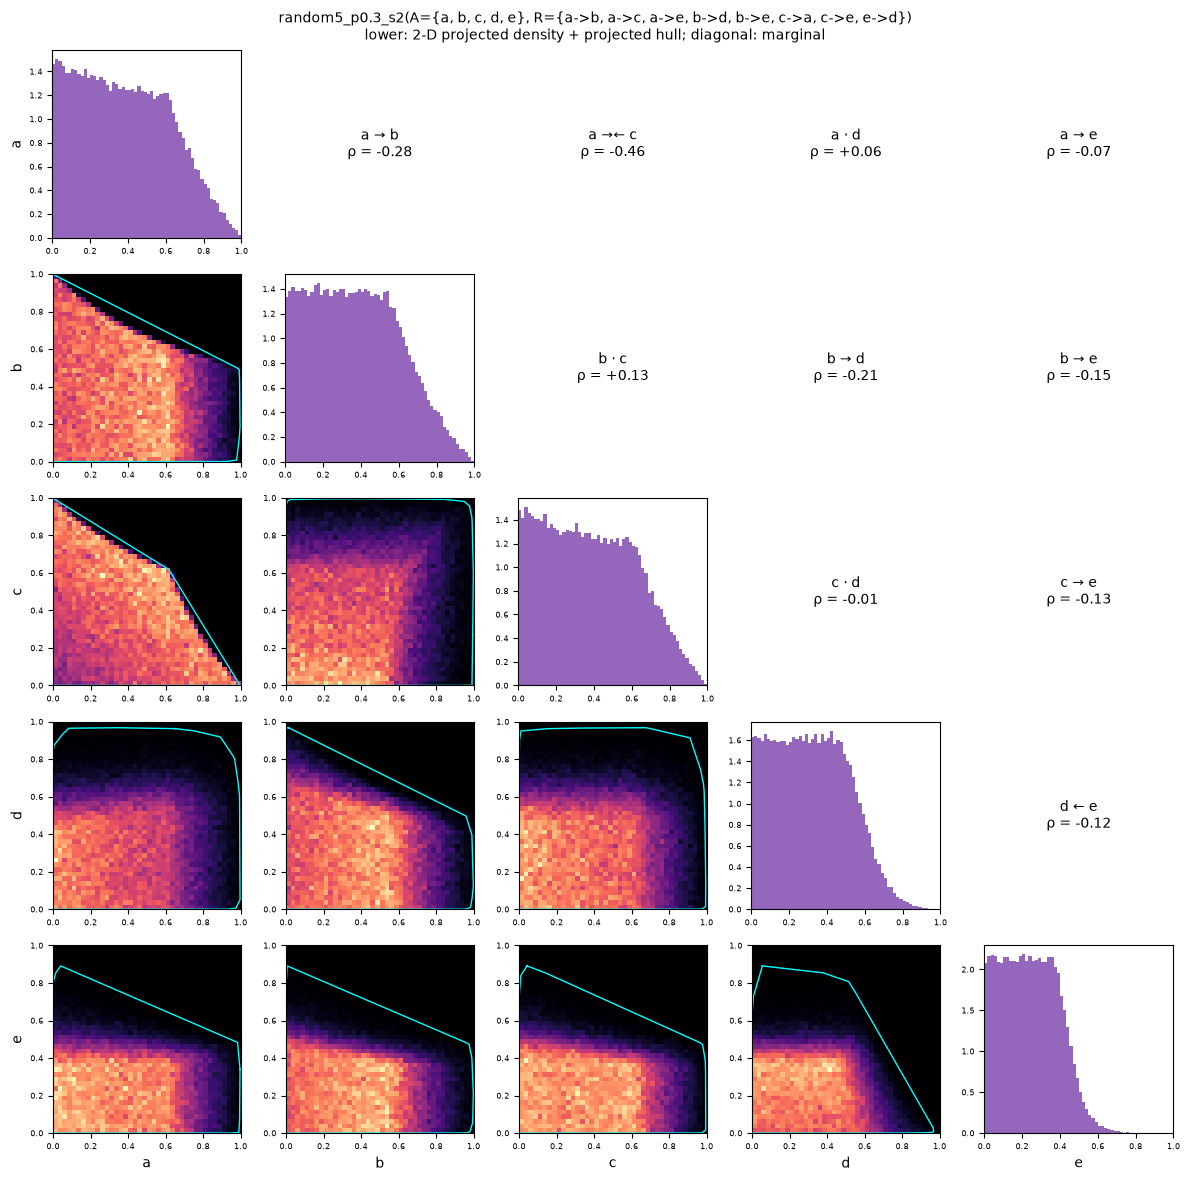

random5_p0.3_s2(A={a, b, c, d, e}, R={a->b, a->c, a->e, b->d, b->e, c->a, c->e, e->d}): done in 63.5s


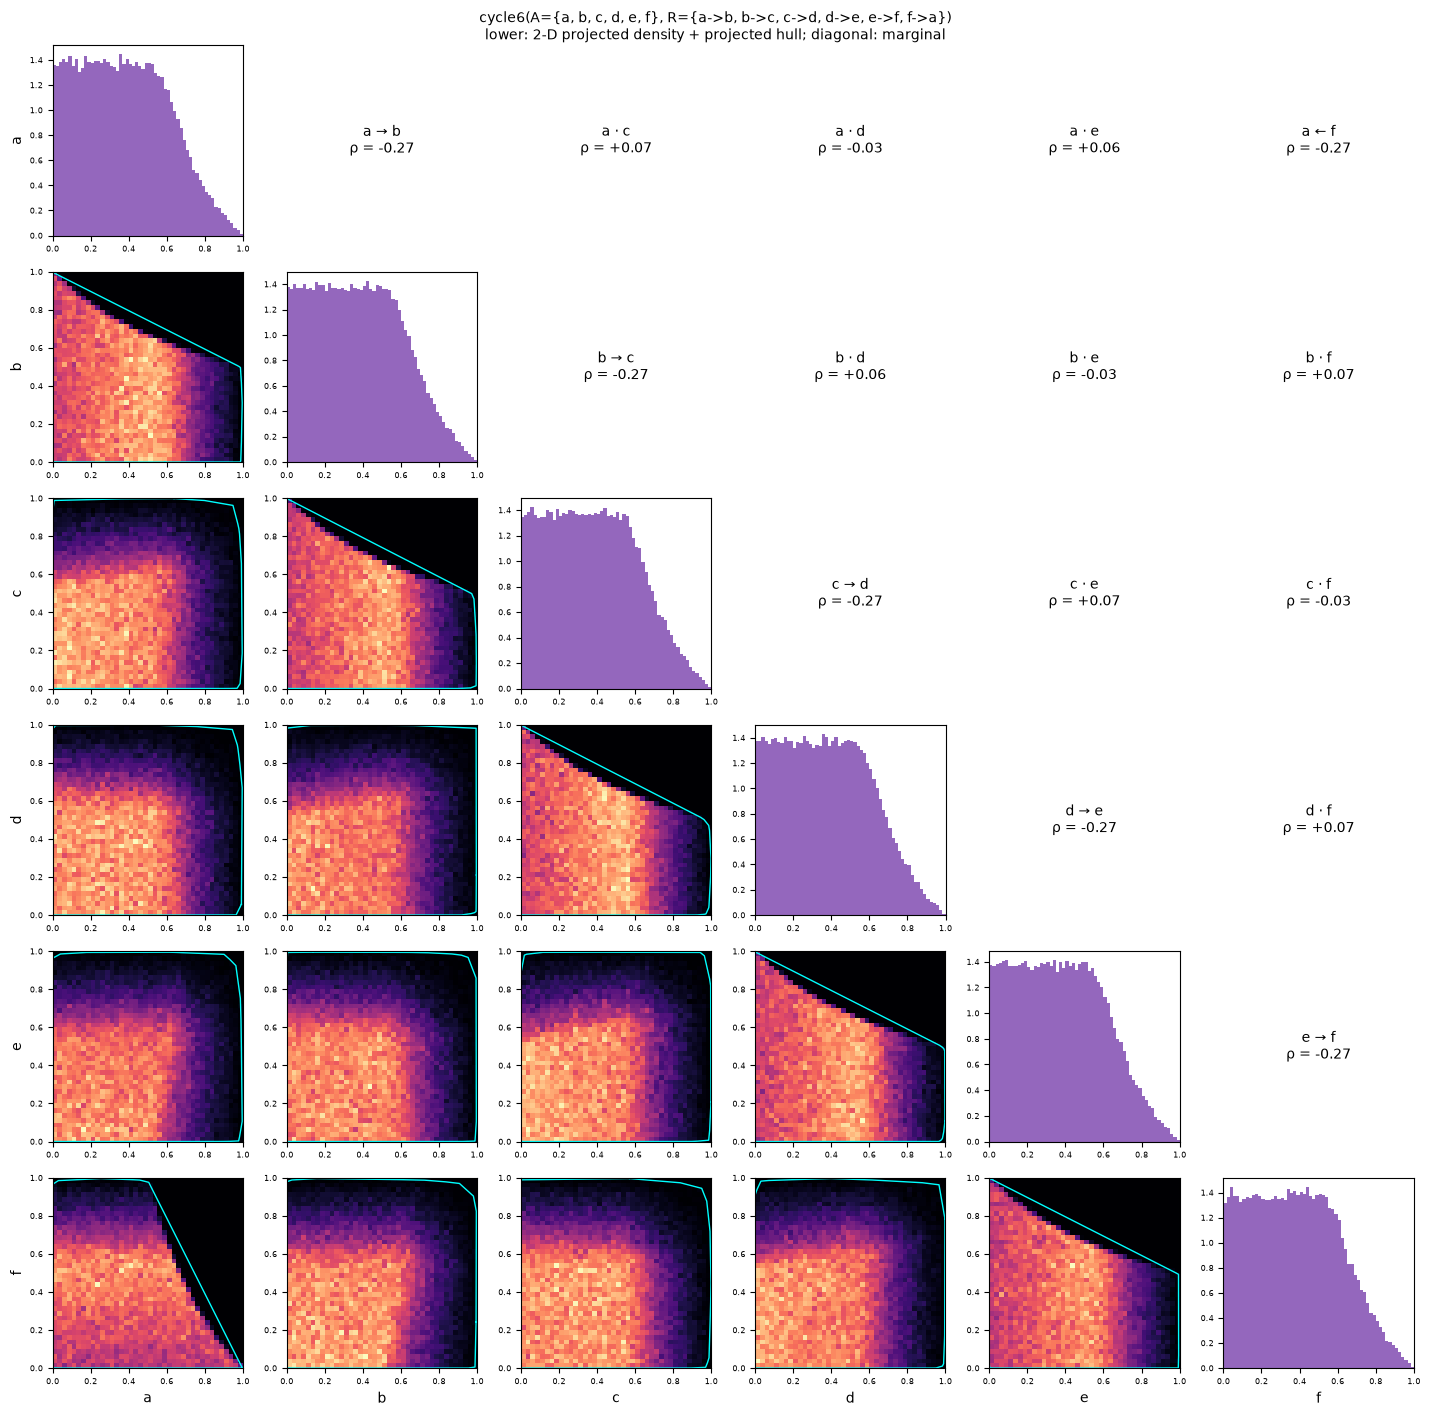

cycle6(A={a, b, c, d, e, f}, R={a->b, b->c, c->d, d->e, e->f, f->a}): done in 632.2s


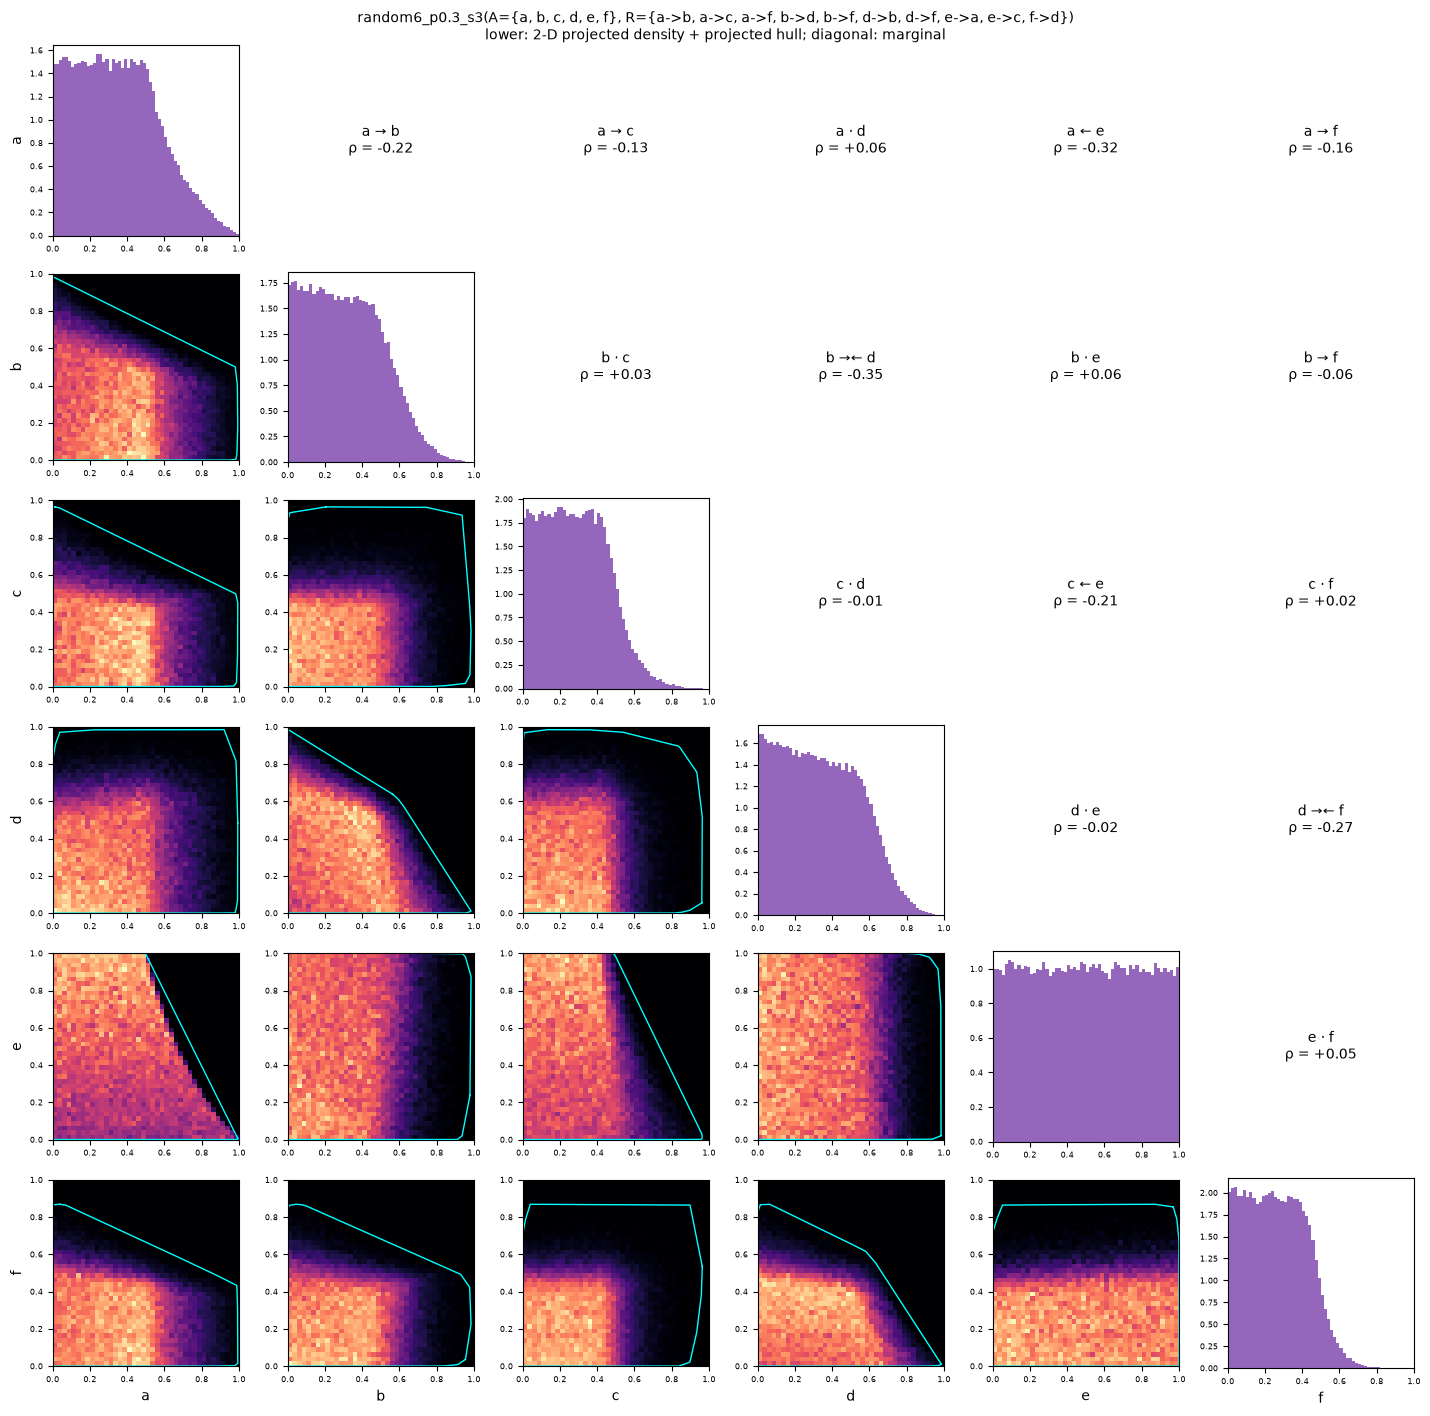

random6_p0.3_s3(A={a, b, c, d, e, f}, R={a->b, a->c, a->f, b->d, b->f, d->b, d->f, e->a, e->c, f->d}): done in 730.2s


In [45]:
afs = [parse(CUSTOM_AF)] if CUSTOM_AF else experiment_frameworks()
rows = []
for af in afs:
    t = time.time()
    rows.append(analyse(af, N_SAMPLES, REPEATS, EPSILON))
    print(f"{af!r}: done in {time.time() - t:.1f}s")

## 6. Tableau récapitulatif

In [46]:
suffix = "_custom" if CUSTOM_AF else ""
(OUT / f"summary{suffix}.json").write_text(json.dumps(rows, indent=2), encoding="utf-8")
write_markdown_table(rows, OUT / f"summary{suffix}.md")
display(Markdown((OUT / f"summary{suffix}.md").read_text(encoding="utf-8")))

| AF | |A| | |R| | iter | vol(hull) | vol(S) | empty in hull | max dens. | TV resample | Jaccard HDR50 | CV vol(hull) |
|---|---|---|---|---|---|---|---|---|---|---|
| isolated2 | 2 | 0 | 1 | 0.9997 | 1.0000 | 0.0000 | 1.0000 | 0.0712 | 0.2911 | 5.80e-05 |
| attack2 | 2 | 1 | 2 | 0.7473 | 0.6936 | 0.0725 | 2.0000 | 0.0589 | 0.6644 | 1.30e-03 |
| mutual2 | 2 | 2 | 25 | 0.6162 | 0.5808 | 0.0585 | 2.2338 | 0.0545 | 0.5588 | 9.06e-04 |
| attack2_self | 2 | 2 | 25 | 0.5153 | 0.5057 | 0.0199 | 2.8249 | 0.0510 | 0.6282 | 5.32e-04 |
| chain3 | 3 | 2 | 3 | 0.5878 | 0.5235 | 0.1127 | 2.9965 | 0.0619 | 0.5661 | 1.64e-03 |
| cycle3 | 3 | 3 | 24 | 0.4720 | 0.4083 | 0.1371 | 4.4012 | 0.0580 | 0.6413 | 2.33e-03 |
| star3 | 3 | 2 | 2 | 0.5993 | 0.5235 | 0.1288 | 2.9965 | 0.0614 | 0.5458 | 4.88e-03 |
| complete3 | 3 | 6 | 34 | 0.3029 | 0.2684 | 0.1138 | 6.6442 | 0.0518 | 0.4890 | 2.74e-03 |
| chain4 | 4 | 3 | 4 | 0.4498 | 0.3882 | 0.1439 | 4.9631 | 0.0621 | 0.5604 | 1.86e-03 |
| cycle4 | 4 | 4 | 24 | 0.3669 | 0.3072 | 0.1697 | 6.5158 | 0.0599 | 0.6107 | 3.10e-03 |
| complete4 | 4 | 12 | 40 | 0.1238 | 0.1073 | 0.1409 | 22.6712 | 0.0472 | 0.4665 | 4.79e-03 |
| random4_p0.4_s1 | 4 | 3 | 25 | 0.4514 | 0.4024 | 0.1150 | 4.4289 | 0.0628 | 0.5663 | 1.36e-03 |
| chain5 | 5 | 4 | 5 | 0.3414 | 0.2890 | 0.1689 | 7.7168 | 0.0626 | 0.5548 | 2.37e-03 |
| cycle5 | 5 | 5 | 24 | 0.2761 | 0.2279 | 0.1895 | 10.3928 | 0.0608 | 0.6086 | 2.69e-03 |
| random5_p0.3_s2 | 5 | 8 | 25 | 0.1645 | 0.1372 | 0.1842 | 19.6973 | 0.0557 | 0.5874 | 7.64e-03 |
| cycle6 | 6 | 6 | 24 | 0.2031 | 0.1697 | 0.1966 | 16.3721 | 0.0615 | 0.6001 | 3.45e-03 |
| random6_p0.3_s3 | 6 | 10 | 29 | 0.1075 | 0.0880 | 0.2168 | 41.4264 | 0.0552 | 0.5941 | 6.79e-03 |


## 7. Convergence et rôle de ε

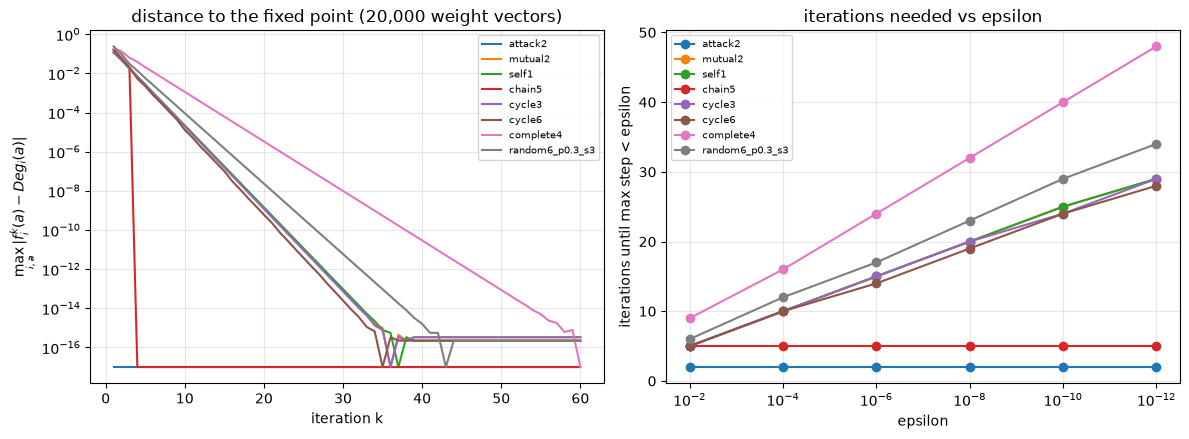

In [47]:
if not CUSTOM_AF:
    conv_afs = [small_frameworks()[k] for k in ("attack2", "mutual2", "self1")] + \
               [chain(5), cycle(3), cycle(6), complete(4), random_af(6, 0.3, 3)]
    conv = convergence_study(conv_afs, OUT / "convergence.png")
    (OUT / "convergence.json").write_text(json.dumps(conv, indent=2), encoding="utf-8")

## 8. Erreur de la carte de densité en fonction de N

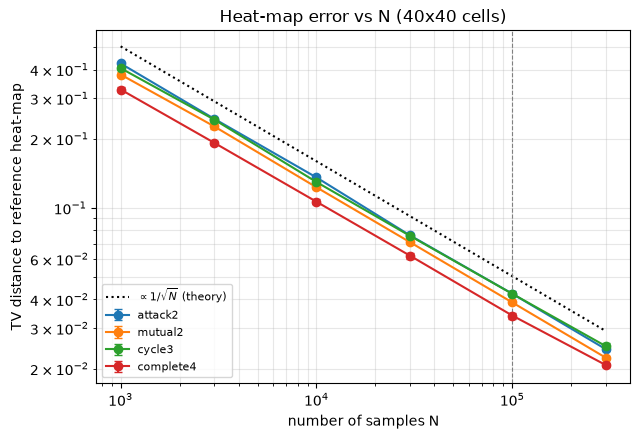

results written to C:\Users\Busin\icaart24-argumentation\results\part3


In [48]:
if not CUSTOM_AF:
    sizes = [1_000, 3_000, 10_000, 30_000, 100_000, 300_000]
    if QUICK:
        sizes = sizes[:3]
    curves = {af.name: tv_vs_sample_size(af, sizes)
              for af in (afs[1], afs[2], cycle(3), complete(4))}
    plot_tv_vs_n(curves, OUT / "tv_vs_n.png")
    (OUT / "tv_vs_n.json").write_text(json.dumps({k: {str(n): v for n, v in c.items()}
                                                  for k, c in curves.items()}, indent=2), encoding="utf-8")
print(f"results written to {OUT.resolve()}")